# 10 · Modellergebnisse und Kapitelabbildungen R1–R5

Dieses Notebook liest die sieben aggregierten Ergebnisdateien aus
`RESULTS/{100,200,500}m/final/`. Es schätzt keine Modelle und benötigt keine Rohdaten.
Nur explizit ausgewählte abgeschlossene Läufe mit der endgültigen H4-Spezifikation
und derselben Pipeline werden verglichen. Fehlende Rasterweiten und nicht schätzbare
Modelle bleiben im Begleitprotokoll sichtbar; ältere Läufe werden nicht ergänzt.

**Ablage wie bei den anderen FIG-Notebooks:**

```text
FIG/Model results/
├── 10_visualize_model_results.ipynb
├── model_results_visualizations.py
├── figure_R1_… / figure_R2_… / figure_R3_… / figure_R4_… / figure_R5_…
├── figure_kompakter_rastervergleich.{png,svg,csv}
├── begleitprotokoll.txt / bildunterschriften.md
├── 100m/  (R1–R5, ergänzende Abbildungen, Ergebnisübersicht)
├── 200m/  (nach Eingang eines verwendbaren Laufs)
└── 500m/  (nach Eingang eines verwendbaren Laufs)
```

Die R-Abbildungen werden mit 16 cm Breite, mindestens 9 pt, ohne Bildtitel als
SVG und als PNG mit 300 dpi in Arial exportiert. Jede hat eine CSV mit den dargestellten
IRR/HR und Intervallgrenzen sowie der eindeutigen Lauf-ID für Anhang E.
R4 verwendet ausschließlich 100 m. Erzeugte Modellabbildungen und Ergebnisdaten
sind Git-ignoriert; Notebook und Darstellungsfunktionen bleiben versioniert.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_DIR = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                   if (p / "ANAL").is_dir() and (p / "FIG").is_dir())
MODEL_FIGURE_DIR = PROJECT_DIR / "FIG" / "Model results"
RUN_NAMES = {100: "final", 200: "final", 500: "final"}
CELL_SIZE = 100  # Detailtabellen im Notebook; Exporte werden für alle verfügbaren Raster erstellt.
sys.path.insert(0, str(PROJECT_DIR))
sys.path.insert(0, str(MODEL_FIGURE_DIR))
from FIG.plotting.apa7 import apa7_axes
import model_results_visualizations as mrv

mrv.set_model_results_style()
MODEL_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
for size in RUN_NAMES:
    (MODEL_FIGURE_DIR / f"{size}m").mkdir(exist_ok=True)

## 1. Ergebnisdateien und Modellstatus prüfen

`RUN_NAMES` legt je Rasterweite genau einen Lauf fest. Sobald die neuen Exporte in
`RESULTS/200m/final` und `RESULTS/500m/final` liegen, genügt **Run All**.
`CELL_SIZE` steuert nur die Detailtabellen. Die Schrift und Achsengestaltung folgen
dem gemeinsamen APA7-Stil in `FIG/plotting/apa7.py` (Arial ist erforderlich; keine automatische Ersatzschrift).

In [2]:
bundles, protocol_notes = mrv.load_bundles(PROJECT_DIR, RUN_NAMES)
if not bundles:
    mrv.write_protocol(bundles, protocol_notes, pd.DataFrame(), MODEL_FIGURE_DIR)
    raise ValueError("Kein verwendbarer abgeschlossener Lauf. Siehe begleitprotokoll.txt.")
if CELL_SIZE not in bundles:
    CELL_SIZE = min(bundles)


def select_bundle(size):
    global info, coefficients, tests, diagnostics, sample, plotdata, covariances
    global RESULT_DIR, OUTPUT_DIR
    bundle = bundles[size]
    info = bundle["info"]
    coefficients, tests = bundle["coefficients"], bundle["tests"]
    diagnostics, sample = bundle["diagnostics"], bundle["sample"]
    plotdata, covariances = bundle["plotdata"], bundle["covariances"]
    RESULT_DIR = bundle["folder"]
    OUTPUT_DIR = MODEL_FIGURE_DIR / f"{size}m"
    OUTPUT_DIR.mkdir(exist_ok=True)


select_bundle(CELL_SIZE)
display(sample)
display(tests.loc[tests.covariance.eq("cell")])
display(diagnostics.loc[diagnostics.status.isin(["FAILED", "REVIEW", "unidentified"])])
print("Ergebnisquelle:", RESULT_DIR)
print("Verfügbare Rasterweiten:", list(bundles))
print("\n".join(protocol_notes))

,model,stage,rows,units,events,excluded,detail,zero_share
0,founding,raw_panel,5332080,133302,74370.0,0,missing cell-quarters=0,NaN
1,founding,model_sample,5331448,133302,74369.0,632,routing=348; missing lag/model values=284,0.987291
2,survival,raw_intervals,4113316,168342,NaN,0,before history exclusions,NaN
3,survival,model_sample,4112838,168326,63416.0,16,"excluded whole histories: routing, missing str...",NaN
4,founding_access_30min,model_sample,5331448,133302,74369.0,0,NaN,NaN
5,founding_centre_control,model_sample,5331448,133302,74369.0,0,NaN,NaN
6,founding_without_2020,model_sample,4798524,133302,66979.0,0,NaN,NaN
7,survival_access_30min,model_sample,4112838,168326,63416.0,0,NaN,NaN


,hypothesis_id,estimate,std_error,ci_lower,ci_upper,p_value,expected_direction,direction_matches,coverage,covariance,...,df,model,specification,sparte,sparte_name,births,detail,sectors_tested,p_holm_sectors,age_years
0,H1,-0.235038,0.026716,-0.287401,-0.182675,1.396738e-18,positive,False,tested,cell,...,NaN,founding_nb2,main,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,H2a,0.284764,0.024863,0.236032,0.333496,2.264116e-30,positive,True,tested,cell,...,NaN,founding_nb2,main,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,H4_routes,-0.002246,0.000375,-0.002980,-0.001511,2.070991e-09,positive,False,tested,cell,...,NaN,founding_nb2,main,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,H4_frequency,0.005277,0.005606,-0.005710,0.016265,3.464931e-01,positive,True,tested,cell,...,NaN,founding_nb2,main,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,H4_no_stop,-0.071826,0.019314,-0.109682,-0.033970,2.001768e-04,negative,True,tested,cell,...,NaN,founding_nb2,main,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,H5,-0.057287,0.008271,-0.073498,-0.041076,4.323496e-12,negative,True,partial,cell,...,NaN,founding_nb2,main,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,H4_joint,NaN,NaN,NaN,NaN,8.191188e-16,NaN,NaN,tested,cell,...,3.0,founding_nb2,main,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,H1,-0.241460,0.026587,-0.293570,-0.189351,1.065430e-19,positive,False,tested,cell,...,NaN,founding_stock_squared,stock_squared,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,H2a,0.291389,0.024874,0.242636,0.340142,1.073636e-31,positive,True,tested,cell,...,NaN,founding_stock_squared,stock_squared,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,H4_routes,-0.002686,0.000423,-0.003515,-0.001858,2.071669e-10,positive,False,tested,cell,...,NaN,founding_stock_squared,stock_squared,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,model,check,status,detail,group,specification,family,n_observations,n_clusters,log_likelihood,...,pearson_dispersion,zero_observed,zero_expected,Fachgruppe_ID,demand_group,births,sparte,sparte_name,births_before,births_retained
4,founding,extreme_residuals,REVIEW,maximum |Pearson|=167; inspect binned fit,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,founding,stock_curvature,REVIEW,quadratic stock beta=0.01774; conditional cell...,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,founding,spatial_residual_dependence,REVIEW,Queen neighbours; five follow-up quarters incl...,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,survival,proportional_hazards,REVIEW,Schoenfeld/event-age correlations are a screen...,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
268,h5,sector_fit,unidentified,Poisson separation: nonzero regressor only on ...,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2,Industrie,NaN,NaN
270,h5,sector_fit,unidentified,Poisson separation: nonzero regressor only on ...,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,4,Bank und Versicherung,NaN,NaN


Ergebnisquelle: C:\Users\leopo\Documents\CO2_Master_Code\CO2_Masterarbeit\RESULTS\100m\final
Verfügbare Rasterweiten: [100]
200 m fehlt: Ergebnisdateien fehlen (laufinfo.json, koeffizienten.csv, hypothesentests.csv, diagnostik.csv, stichprobe.csv, plotdaten.parquet, kovarianzen.parquet).
500 m fehlt: Ergebnisdateien fehlen (laufinfo.json, koeffizienten.csv, hypothesentests.csv, diagnostik.csv, stichprobe.csv, plotdaten.parquet, kovarianzen.parquet).


## 2. Kapitel 5: Koeffizientenplots R1–R5

Die Hauptinferenz verwendet ausschließlich Zellcluster. H1 und die H3-Differenz
werden einschließlich ihrer Intervalle direkt aus der Hypothesentabelle übernommen.
Die Gruppen-A/C-Kontraste kommen aus den exportierten Plotdaten, nicht aus einer
erneuten Koeffizientendifferenz. IRR und HR sind exponentierte Schätzwerte; auch
beide Intervallgrenzen werden exponentiert. Die Referenz liegt bei 1.

- **R1:** Nachfrage, Unternehmensumfeld und eigene Zellbevölkerung; der Eigenbestand bleibt ausgeklammert.
- **R2:** Bevölkerungskontraste der Gruppen A und C und deren Verhältnis (H3).
- **R3:** ÖV-Erschließung; Linienzahl auf zehn Linien umgerechnet.
- **R4:** Autobahnfahrzeit in sieben Sparten, nur 100 m, mit NB2-Gesamtmodell als grauem Referenzband.
- **R5:** Cox-Modell, getrennt nach Autoumfeld und eigener Rasterzelle.

100 m erscheint als kräftiger Kreis, 200 m als helleres Quadrat und 500 m als
offenes Dreieck. Erwartungsrichtungen und erkl?rende Fu?texte stehen au?erhalb der Abbildungen.
Titel, Quellen und gemeinsame Wald-Tests stehen in den separaten Bildunterschriften.

In [3]:
chapter_data = mrv.prepare_chapter_data(bundles, protocol_notes)
mrv.write_protocol(bundles, protocol_notes, chapter_data, MODEL_FIGURE_DIR)
display(chapter_data.rename(columns={"figure": "Abbildung", "resolution": "Rasterweite",
                                    "label": "Merkmal", "status": "Status"})[
    ["Abbildung", "Rasterweite", "Merkmal", "Status"]])

,Abbildung,Rasterweite,Merkmal,Status
0,R1,100,"Bevölkerung im Autoumfeld, bei gleichem Bestand",dargestellt
1,R1,100,"Unternehmensbestand im Autoumfeld, bei gleiche...",dargestellt
2,R1,100,Bevölkerung der eigenen Rasterzelle (Vorjahr),dargestellt
3,R2,100,Gruppe A: hohe lokale Nachfrageabhängigkeit (n...,dargestellt
4,R2,100,Gruppe C: geringe lokale Nachfrageabhängigkeit...,dargestellt
5,R2,100,Differenz A gegenüber C,dargestellt
6,R3,100,"Linienzahl in 10 Gehminuten, je 10 Linien",dargestellt
7,R3,100,Abfahrtsfrequenz in 10 Gehminuten (logarithmiert),dargestellt
8,R3,100,Keine Haltestelle in 10 Gehminuten,dargestellt
9,R5,100,Branchengleicher Unternehmensbestand,dargestellt


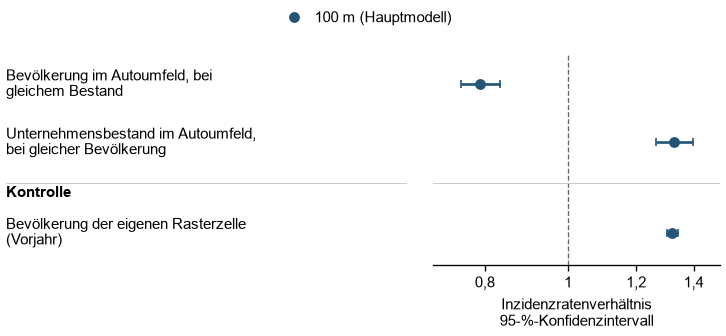

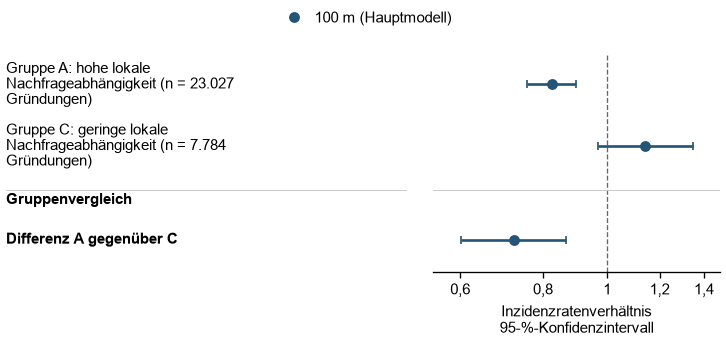

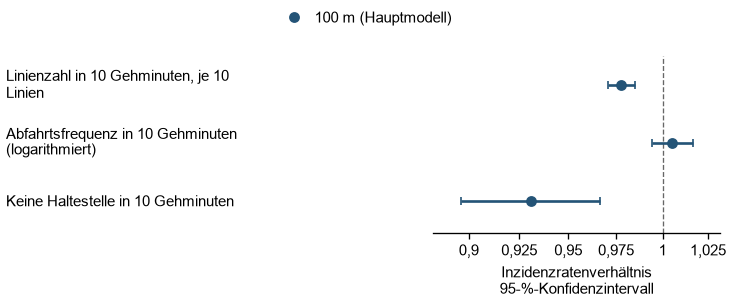

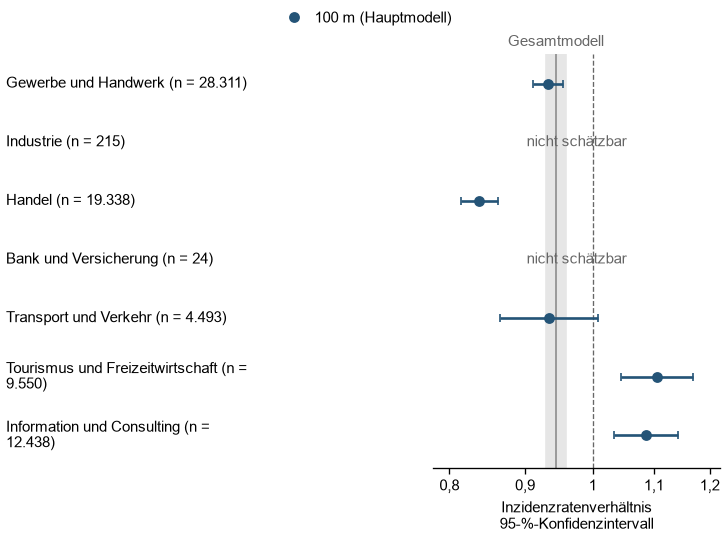

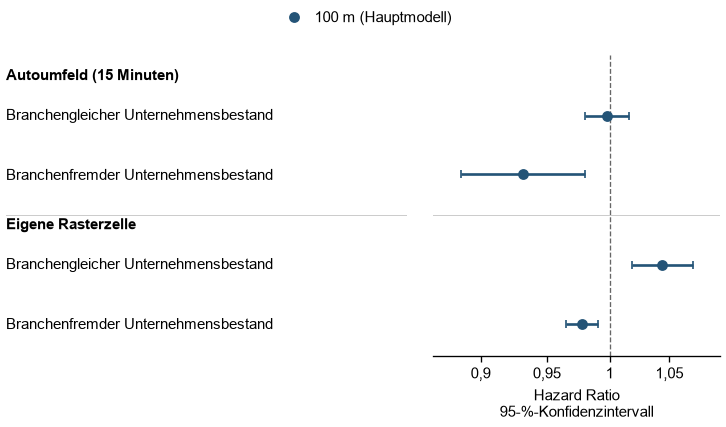

In [4]:
# Vergleichsausgaben neben dem Notebook (R4 bleibt auf 100 m beschränkt).
for fig in mrv.create_chapter_figures(chapter_data, MODEL_FIGURE_DIR):
    display(fig)
    plt.close(fig)

# Dieselben Kapitelabbildungen für jede einzelne verfügbare Rasterweite.
for size in bundles:
    for fig in mrv.create_chapter_figures(chapter_data, MODEL_FIGURE_DIR / f"{size}m", [size]):
        plt.close(fig)

## 3. Kompakter Rastervergleich

Der Überblick fasst die zentralen Kontraste aller **verfügbaren** Rasterweiten
zusammen. Die Blöcke kennzeichnen IRR im Gründungsmodell und HR im Cox-Modell;
die H3-Zeile ist ein Verhältnis zweier IRR. Solange nur 100 m vorliegt, zeigt die
Abbildung ausschließlich diesen Lauf. Fehlende Varianten stehen im Begleitprotokoll.

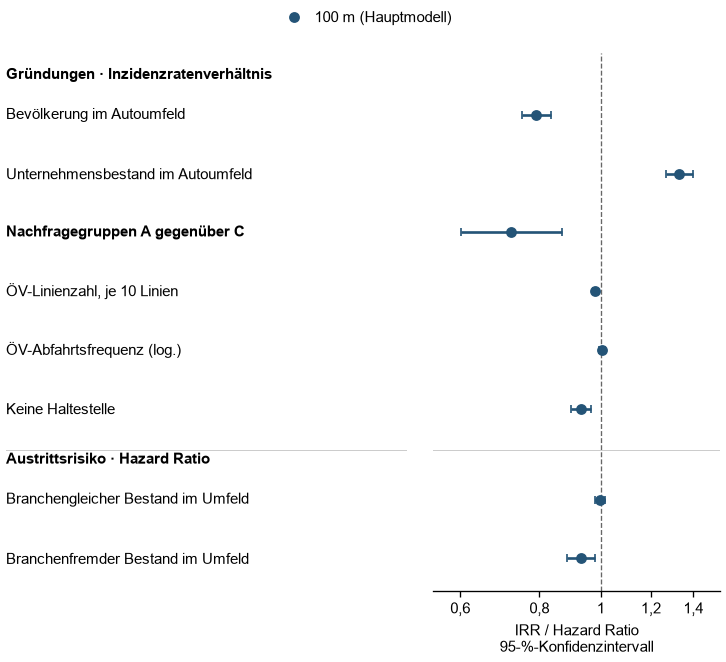

In [5]:
fig = mrv.compact_comparison(chapter_data, MODEL_FIGURE_DIR)
if fig is not None:
    display(fig)
    plt.close(fig)

## 4. Ergänzende Abbildungen und Modellgrenzen je Rasterweite

Die sieben bisherigen Abbildungen bleiben erhalten: Gründungseffekte, Cox-Effekte,
H3-Gruppen, Abfahrtsfrequenz, Sparten, H1-Sensitivitäten und räumliche Residuen.
Die Forest-Plots zeigen jetzt ebenfalls IRR/HR auf logarithmischer Achse. Das
Abfahrtsprofil hält die übrigen Merkmale und Haltestellenverfügbarkeit konstant.
Diagnostische Hinweise, PH-Screens und nicht schätzbare Sparten stehen zusätzlich
in `ergebnisuebersicht.md` und im Begleitprotokoll.

In [6]:
def save_figure(fig, name):
    fig.tight_layout()
    for extension in ["png", "svg"]:
        fig.savefig(OUTPUT_DIR / f"{name}.{extension}", dpi=300, bbox_inches="tight")
    display(fig)
    plt.close(fig)


def forest(table, labels, filename, hazard=False):
    table = table.dropna(subset=["estimate", "ci_lower", "ci_upper"])
    if table.empty: return
    fig, ax = plt.subplots(figsize=(6.5, max(2.8, .45*len(table)+1.2)))
    point = np.exp(table.estimate)
    lower = np.exp(table.ci_lower)
    upper = np.exp(table.ci_upper)
    ax.errorbar(point, np.arange(len(table)), xerr=[point-lower, upper-point],
        fmt="o", color="black", capsize=3, markersize=4)
    mrv.ratio_axis(ax, (lower.min(), upper.max()))
    ax.set_yticks(np.arange(len(table)), [labels(row) for row in table.itertuples()])
    ax.tick_params(axis="y", labelleft=True)
    ax.invert_yaxis()
    ax.set_xlabel("Hazard Ratio mit 95%-Konfidenzintervall" if hazard else "Inzidenzratenverhältnis mit 95%-Konfidenzintervall")
    apa7_axes(ax)
    save_figure(fig, filename)


def subset_tests(model, identifiers):
    if mrv.model_problem(bundles[info["resolution_m"]], model):
        return tests.iloc[:0]
    return tests.loc[tests.model.eq(model) & tests.hypothesis_id.isin(identifiers) & tests.covariance.eq("cell")]

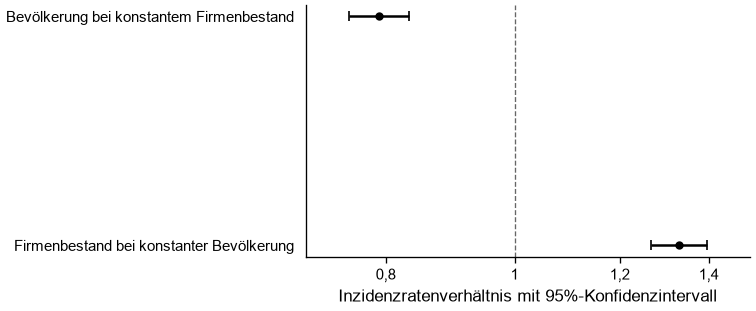

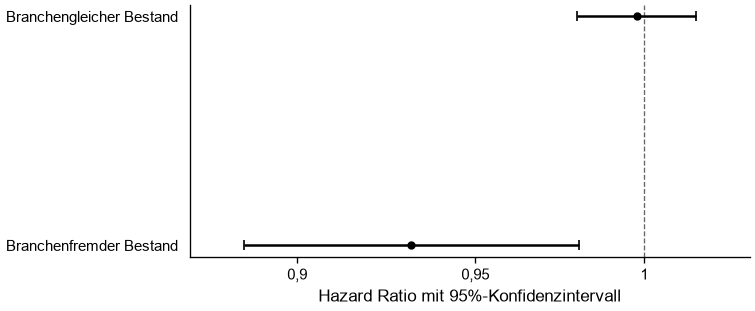

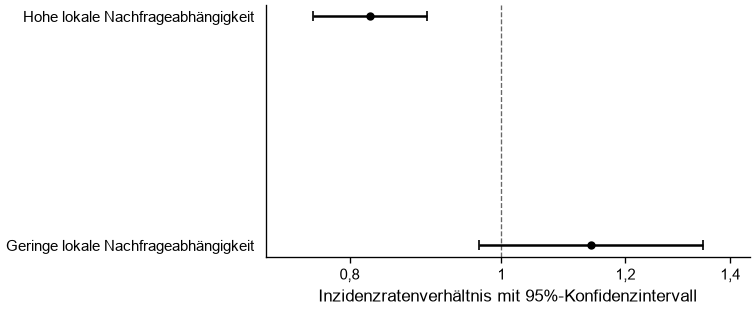

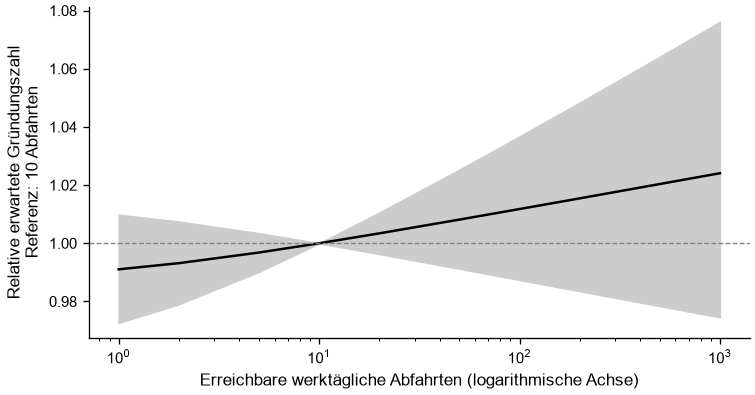

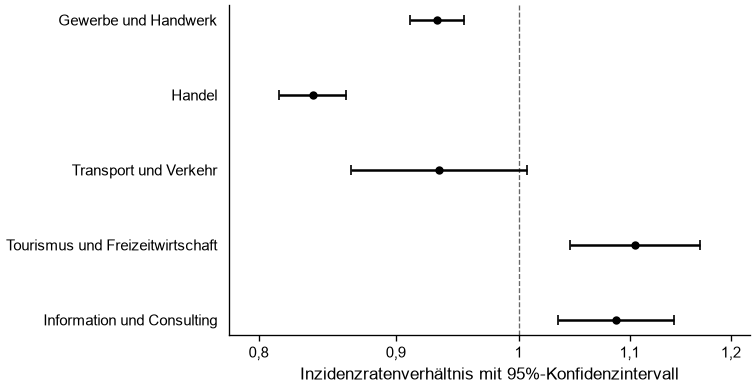

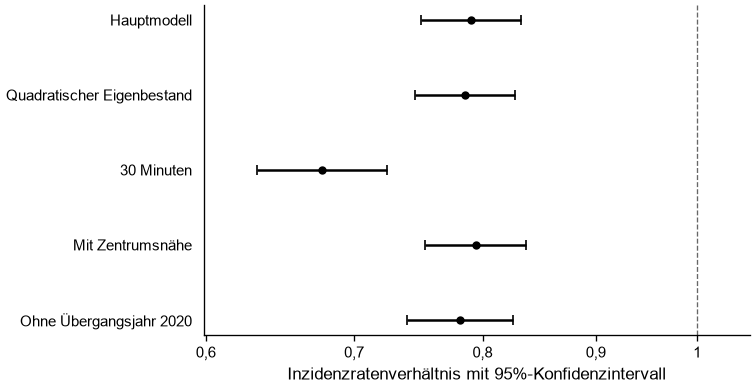

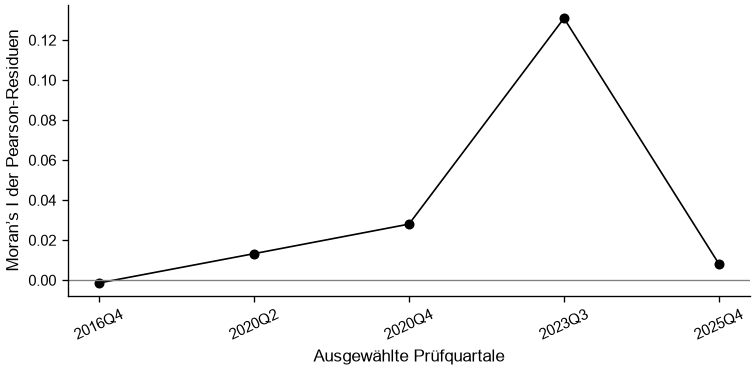

Abbildungen und Überblick: C:\Users\leopo\Documents\CO2_Master_Code\CO2_Masterarbeit\FIG\Model results\100m


In [7]:
for size in bundles:
    select_bundle(size)
    count = subset_tests("founding_nb2", ["H1", "H2a"])
    labels = {"H1": "Bevölkerung bei konstantem Firmenbestand", "H2a": "Firmenbestand bei konstanter Bevölkerung"}
    forest(count, lambda r: labels[r.hypothesis_id], "01_gruendungseffekte")
    survival = subset_tests("survival_cox", ["H2b", "H2c"])
    labels_cox = {"H2b": "Branchengleicher Bestand", "H2c": "Branchenfremder Bestand"}
    forest(survival, lambda r: labels_cox[r.hypothesis_id], "02_cox_effekte", hazard=True)

    h3 = plotdata.loc[plotdata.plot_type.eq("h3_population")].copy()
    if not h3.empty and all(mrv.model_problem(bundles[size], m) is None for m in ["h3_A", "h3_C"]):
        h3["estimate"] = h3.population_effect
        forest(h3, lambda r: {"A":"Hohe lokale Nachfrageabhängigkeit", "C":"Geringe lokale Nachfrageabhängigkeit"}[r.group], "03_h3_gruppeneffekte")

    h4 = plotdata.loc[plotdata.plot_type.eq("h4_frequency")].sort_values("departures")
    if not h4.empty and mrv.model_problem(bundles[size], "founding_nb2") is None:
        fig, ax = plt.subplots(figsize=(6.5, 3.5))
        ax.plot(h4.departures, h4.relative_count, color="black")
        ax.fill_between(h4.departures.to_numpy(dtype=float), h4.ci_lower.to_numpy(dtype=float),
                        h4.ci_upper.to_numpy(dtype=float), color=".8")
        ax.axhline(1, color=".5", linestyle="--", linewidth=.8)
        ax.set_xscale("log")
        ax.set(xlabel="Erreichbare werktägliche Abfahrten (logarithmische Achse)",
               ylabel="Relative erwartete Gründungszahl\nReferenz: "+f"{h4.reference.iloc[0]:g} Abfahrten")
        apa7_axes(ax)
        save_figure(fig, "04_h4_abfahrtsfrequenz")

    h5 = tests.loc[tests.model.eq("h5_sectors") & tests.hypothesis_id.eq("H5_sector")].copy()
    h5 = h5.loc[h5.covariance.eq("cell") & h5.sparte.map(
        lambda sector: pd.notna(sector) and mrv.model_problem(bundles[size], f"h5_{int(sector)}") is None)].sort_values("sparte")
    forest(h5, lambda r: r.sparte_name, "05_h5_sparten")

    models = ["founding_nb2", "founding_stock_squared", "founding_access_30min", "founding_centre_control", "founding_without_2020"]
    names = {"founding_nb2":"Hauptmodell", "founding_stock_squared":"Quadratischer Eigenbestand",
             "founding_access_30min":"30 Minuten", "founding_centre_control":"Mit Zentrumsnähe",
             "founding_without_2020":"Ohne Übergangsjahr 2020"}
    comparison = tests.loc[tests.model.isin(models) & tests.hypothesis_id.eq("H1")].copy()
    comparison = comparison.loc[comparison.covariance.eq("cell") & comparison.model.map(
        lambda model: mrv.model_problem(bundles[size], model) is None)]
    comparison["order"] = comparison.model.map({m:i for i,m in enumerate(models)})
    forest(comparison.sort_values("order"), lambda r: names[r.model], "06_h1_sensitivitaeten")
    moran = plotdata.loc[plotdata.plot_type.eq("moran")].sort_values("period")
    if not moran.empty:
        fig, ax = plt.subplots(figsize=(6.5, 3.3))
        ax.plot(np.arange(len(moran)), moran.I, "o-", color="black", linewidth=1)
        ax.axhline(0, color=".5", linewidth=.8)
        ax.set_xticks(np.arange(len(moran)), moran.period, rotation=25)
        ax.set(xlabel="Ausgewählte Prüfquartale", ylabel="Moran’s I der Pearson-Residuen")
        apa7_axes(ax)
        save_figure(fig, "07_raeumliche_residuen")

    def md_table(frame):
        frame = frame.fillna("")
        lines = ["| " + " | ".join(map(str, frame.columns)) + " |",
                 "| " + " | ".join(["---"]*len(frame.columns)) + " |"]
        lines += ["| " + " | ".join(str(v).replace("|", "/").replace("\n", " ") for v in row) + " |"
                  for row in frame.itertuples(index=False, name=None)]
        return "\n".join(lines)

    selected = tests.loc[tests.model.isin(["founding_nb2", "survival_cox", "h3_A_vs_C", "h5_sectors"])].copy()
    columns = [c for c in ["model", "hypothesis_id", "sparte_name", "covariance", "estimate", "ci_lower", "ci_upper", "statistic", "df", "p_value", "p_holm_sectors", "coverage"] if c in selected]
    overview = "# Ergebnisüberblick\n\n"+md_table(selected[columns].round(4))
    overview += "\n\n## Stichprobe\n\n"+md_table(sample)
    flags = diagnostics.loc[diagnostics.status.isin(["FAILED", "REVIEW", "unidentified"])]
    overview += "\n\n## Prüfbedarf\n\n"+md_table(flags)
    overview += ("\n\nAlle Zusammenhänge sind bedingt auf die Modellspezifikation. Zell- und räumliche Blockintervalle "
        "sowie PH- und Funktionsformprüfungen sind gemeinsam zu beurteilen. H4 ist gemäß der aktualisierten "
        "Definition operationalisiert; dies bedeutet keine empirische Bestätigung. H5-Spartenunterschiede "
        "werden mit dem gemeinsamen Gleichheitstest beurteilt. Nicht schätzbare Sparten bleiben ausgewiesen. "
        "Bevölkerungsrückrechnung und jährliche Infrastruktursnapshots begrenzen die zeitliche Interpretation.\n")
    overview += "\nAltersabhängige Sensitivität: "+json.dumps(info.get("age_sensitivity", {}), ensure_ascii=False)
    overview += "\n30-Minuten-Cox-Sensitivität: "+json.dumps(info.get("accessibility_sensitivity", {}), ensure_ascii=False)
    (OUTPUT_DIR / "ergebnisuebersicht.md").write_text(overview+"\n", encoding="utf-8")
    print("Abbildungen und Überblick:", OUTPUT_DIR)

select_bundle(CELL_SIZE)

In [8]:
mrv.write_protocol(bundles, protocol_notes, chapter_data, MODEL_FIGURE_DIR)
print("Abbildungen und CSVs:", MODEL_FIGURE_DIR)
print("Wald-Tests, fehlende Varianten und Umrechnungen: begleitprotokoll.txt")
print("Vorschläge für Word: bildunterschriften.md")

Abbildungen und CSVs: C:\Users\leopo\Documents\CO2_Master_Code\CO2_Masterarbeit\FIG\Model results
Wald-Tests, fehlende Varianten und Umrechnungen: begleitprotokoll.txt
Vorschläge für Word: bildunterschriften.md
